# ThAr IP analysis for jaxstar

This notebook analyzes the bundled 107-strip summed ThAr spectrum to estimate the instrumental profile (IP) for use in jaxstar. It uses the `lab_centered` model, keeping the wavelength solution fixed and measuring profile offsets relative to laboratory wavelengths.

## Run and save in one call

Install the plotting dependency with `pip install -e '.[analysis]'` from the repository root (or use the `notebook` extra).
To run this entire analysis and save all results and figures, use the following call from this notebook's directory.
It returns the same `FitResult` used below. Set `output_dir` to an empty or new directory of your choice.
The subsequent cells show the individual steps for interactive inspection; they are an alternative to this call.

```python
from gaoesrvip import analyze_thar_ip_2g

common = analyze_thar_ip_2g(
    thar="../data/ThAr20251107_2.center.fits",
    wavelength_file="../data/ecThAr20251107_2.center",
    fit_spectrum="../data/ThAr20251107_2_ecfw.fits",
    output_dir="./results/thar_ip_analysis_for_jaxstar",
    orders=[104, 105],
    gain=1.935, read_noise=4.0, saturation=5000,
)
```

Defaults match the steps below: `mode="common"`, `model="lab_centered"`, `tophat=False`, and a linear baseline.
Selection and MCMC settings (for example `half_window`, `baseline_degree`, `warmup`, `samples`, and `seed`) can be supplied as keywords.

## Setup

Import the fitting and plotting tools.

To fit the central spectrum instead, omit `fit_spectrum` from the `select_lines` or `analyze_thar_ip_2g` call.
Line selection uses the central spectrum and its database in either case.

In [1]:
import matplotlib.pyplot as plt
import corner
from gaoesrvip import select_lines, fit, save_analysis_figures

## Input data

Choose the central ThAr spectrum and database for line selection, the summed spectrum to fit, and the echelle orders.

In [2]:
thar = "../data/ThAr20251107_2.center.fits"
wavelength_file = "../data/ecThAr20251107_2.center"
fit_spectrum = "../data/ThAr20251107_2_ecfw.fits"
orders = [104, 105] # choose appropriate ones

## Select lines

Select isolated, unsaturated lines on the central spectrum and extract their profiles from the sum. Set the detector gain, read noise, and central-spectrum selection limit for your input data.

In [3]:
data = select_lines(thar, wavelength_file, fit_spectrum=fit_spectrum, orders=orders, 
                    gain=1.935, read_noise=4.0, saturation=5000)

## Fit the common IP

Fit a shared two-Gaussian IP for each order using the `lab_centered` model. Each line has its own flux and baseline; `tophat=False` disables pixel integration.

In [4]:
common = fit(data, mode="common", model="lab_centered", tophat=False,
             warmup=1000, samples=1000, chains=2)

Order 104: 24 lines, common, lab_centered, MCMC, tophat=False, baseline_degree=1



  0%|          | 0/2000 [00:00<?, ?it/s]


warmup:   5%|▌         | 100/2000 [00:06<02:07, 14.85it/s, 1023 steps of size 1.86e-05. acc. prob=0.88]


warmup:  10%|█         | 200/2000 [00:09<01:20, 22.42it/s, 127 steps of size 2.49e-02. acc. prob=0.92] 


warmup:  15%|█▌        | 300/2000 [00:10<00:50, 33.47it/s, 127 steps of size 4.68e-02. acc. prob=0.93]

...


sample:  90%|█████████ | 1800/2000 [00:31<00:02, 69.86it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample:  95%|█████████▌| 1900/2000 [00:33<00:01, 69.97it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample: 100%|██████████| 2000/2000 [00:34<00:00, 69.97it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample: 100%|██████████| 2000/2000 [00:34<00:00, 57.57it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
 local_scaled[0,0]      0.40      0.00      0.40      0.40      0.40   2946.90      1.00
 local_scaled[0,1]      0.50      0.00      0.50      0.50      0.50   3174.82      1.00
 local_scaled[0,2]      0.10      0.00      0.10      0.10      0.11   2688.96      1.00
 local_scaled[1,0]      0.41      0.00      0.41      0.40      0.41   2771.83      1.00
 local_scaled[1,1]      0.50      0.00      0.50      0.50      0.50   3417.07      1.00
 local_scaled[1,2]      0.11      0.00      0.11      0.11      0.11   3041.76      1.00
 local_scaled[2,0]      0.40      0.00      0.40      0.40      0.40   3515.30      1.00
 local_scaled[2,1]      0.50      0.00      0.50      0.50      0.50   3218.49      1.00
 local_scaled[2,2]      0.10      0.00      0.10      0.10      0.10   3588.22      1.00
 local_scaled[3,0]      0.40      0.00      0.40      0.40      0.40   2905.18      1.00
 local_scaled[3,1]  

## Inspect line fits

Compare each observed line with its fitted profile and baseline in the original flux units.

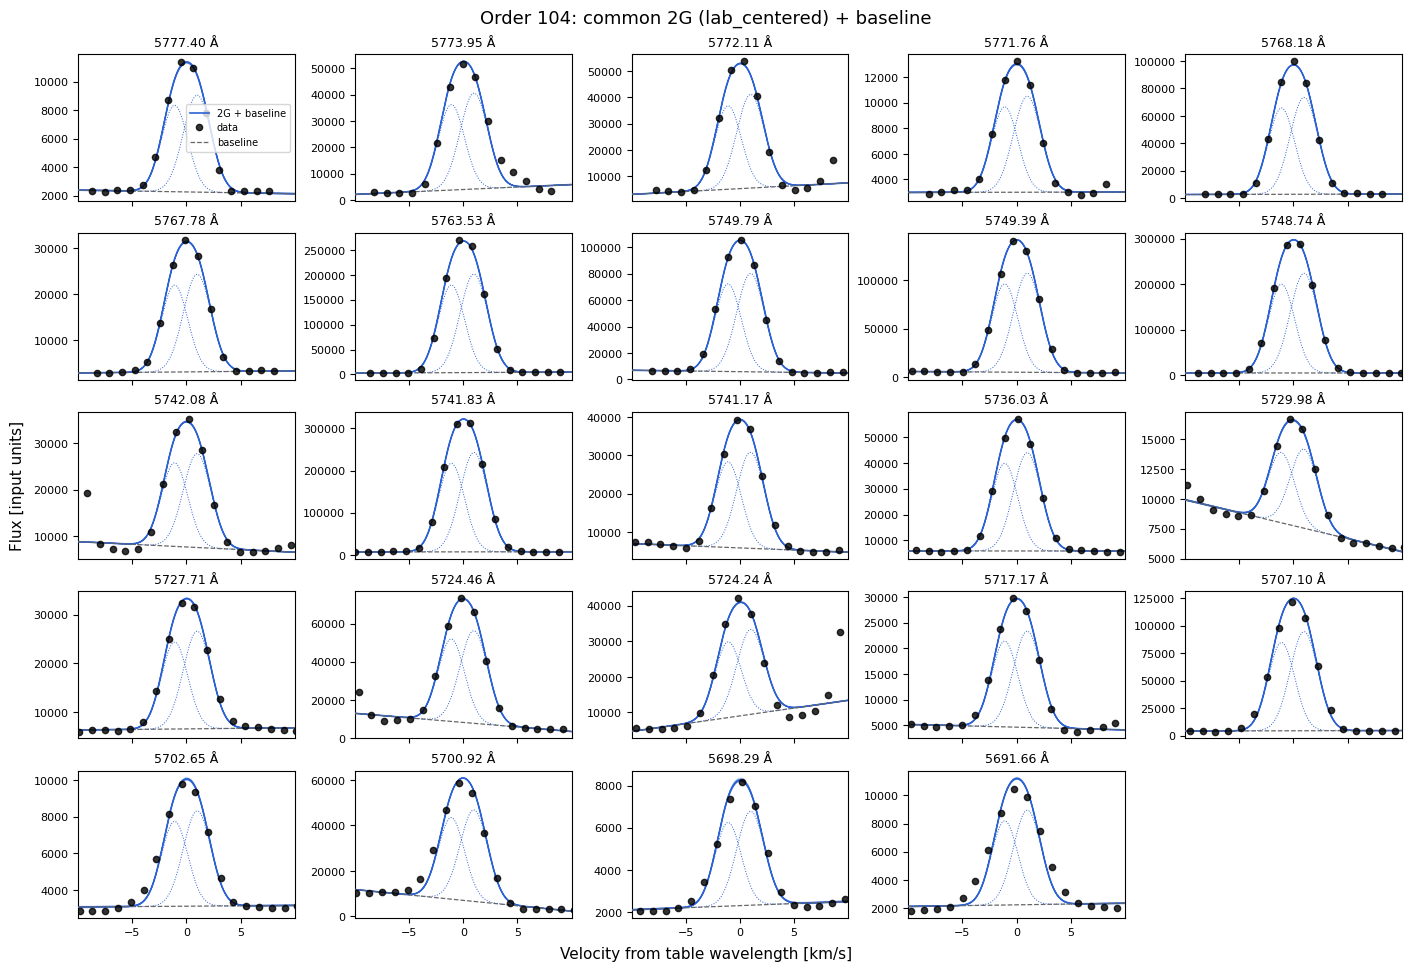

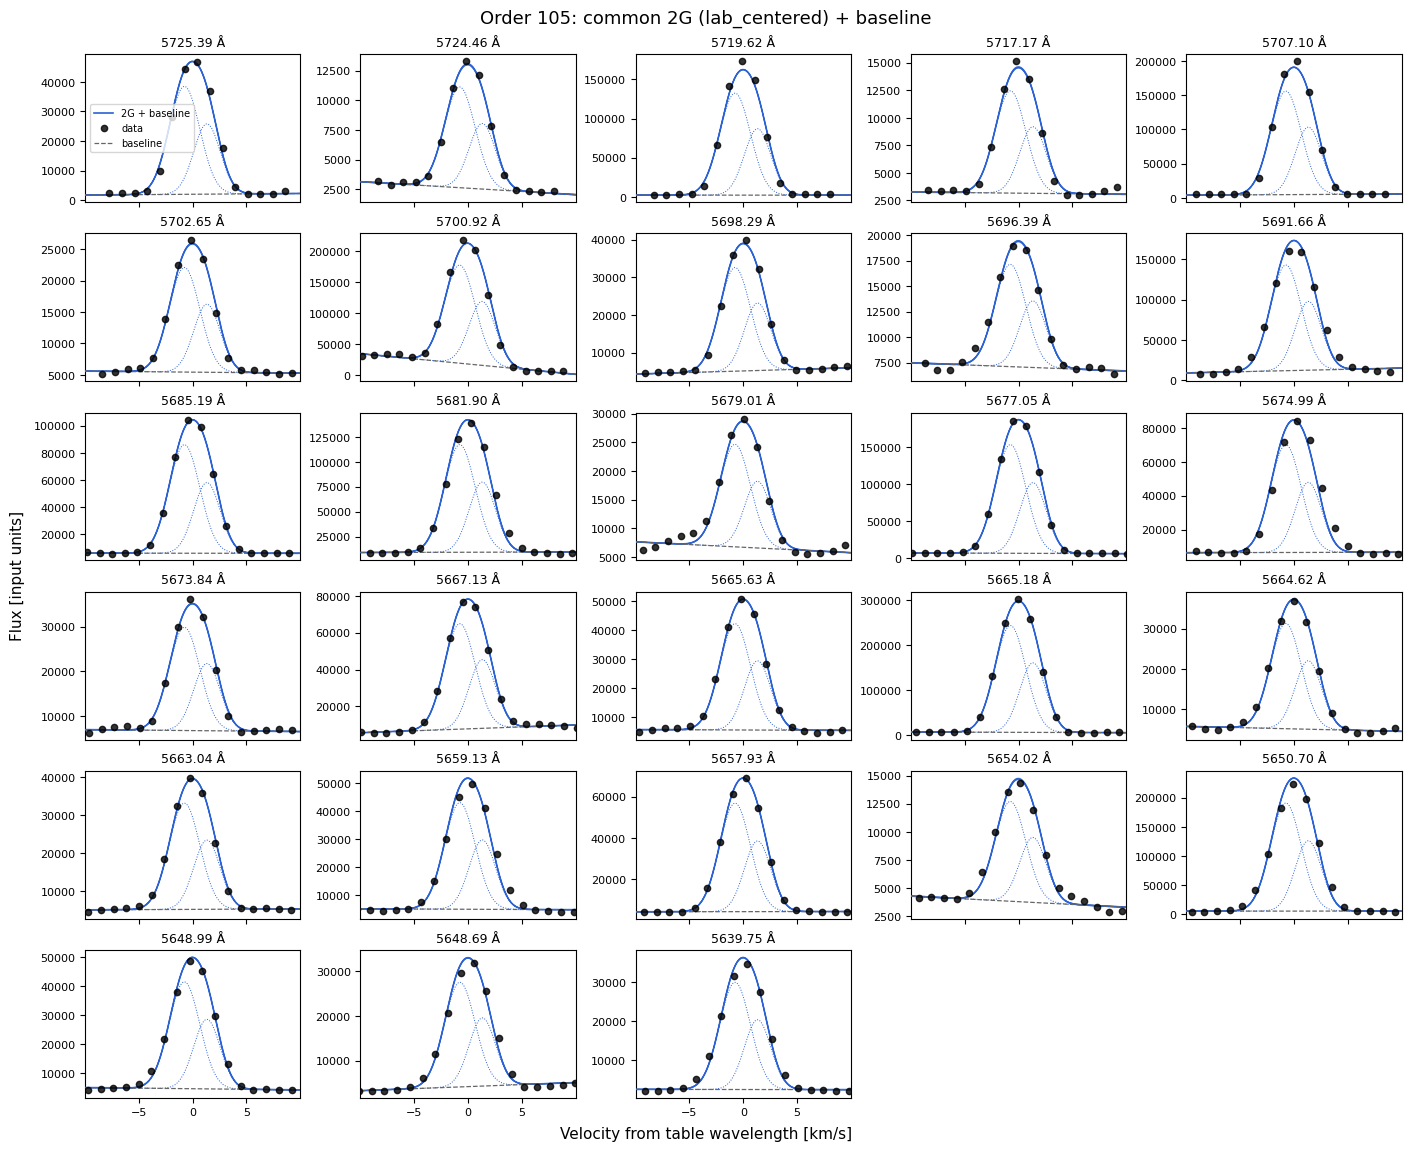

In [5]:
common.plot_lines(include_baseline=True);

## Overlay line profiles

Compare normalized line profiles and residuals within each order. Zero velocity is the laboratory wavelength, so the fitted offsets are retained.

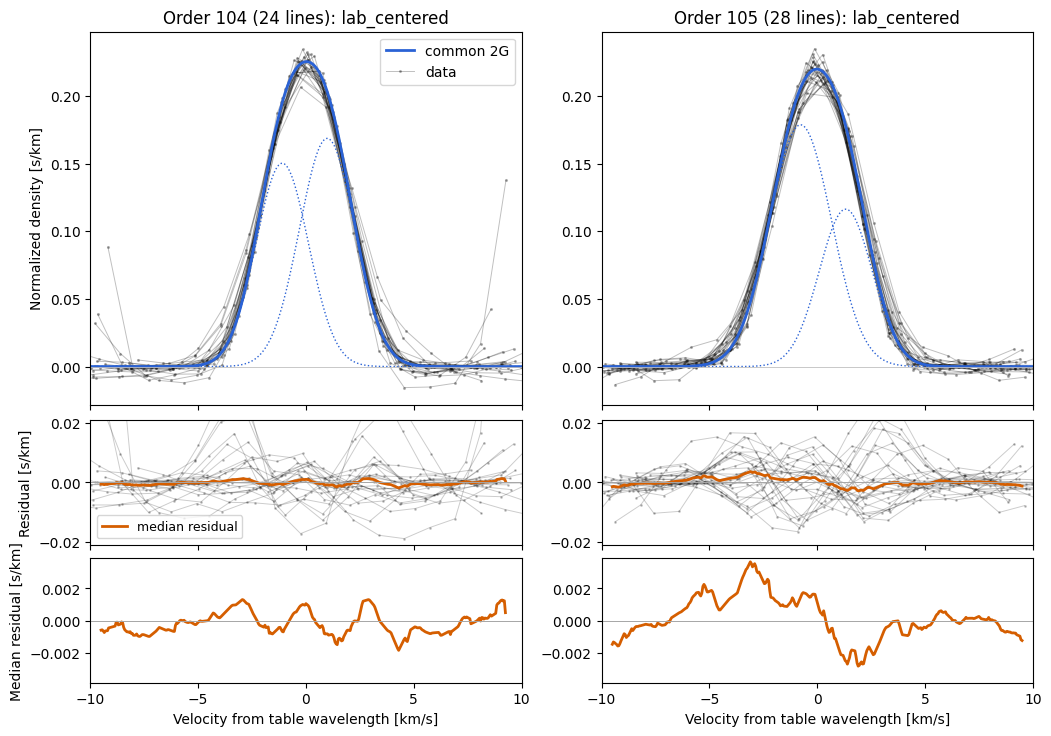

In [6]:
common.overlay();

## Inspect posterior samples

Use corner plots to inspect the uncertainties and correlations of the shared IP parameters in each order.

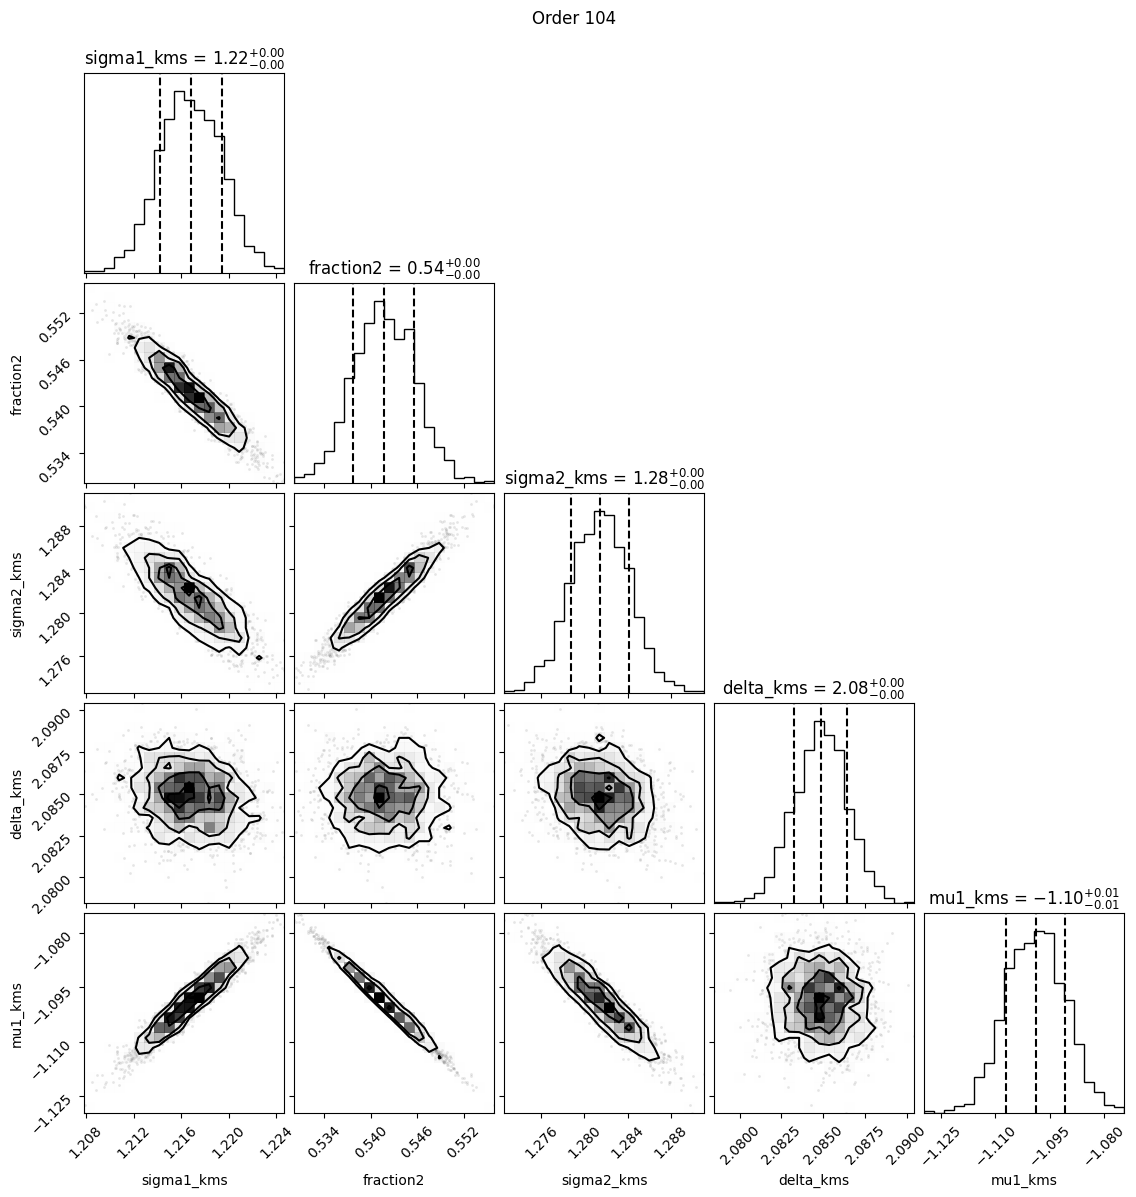

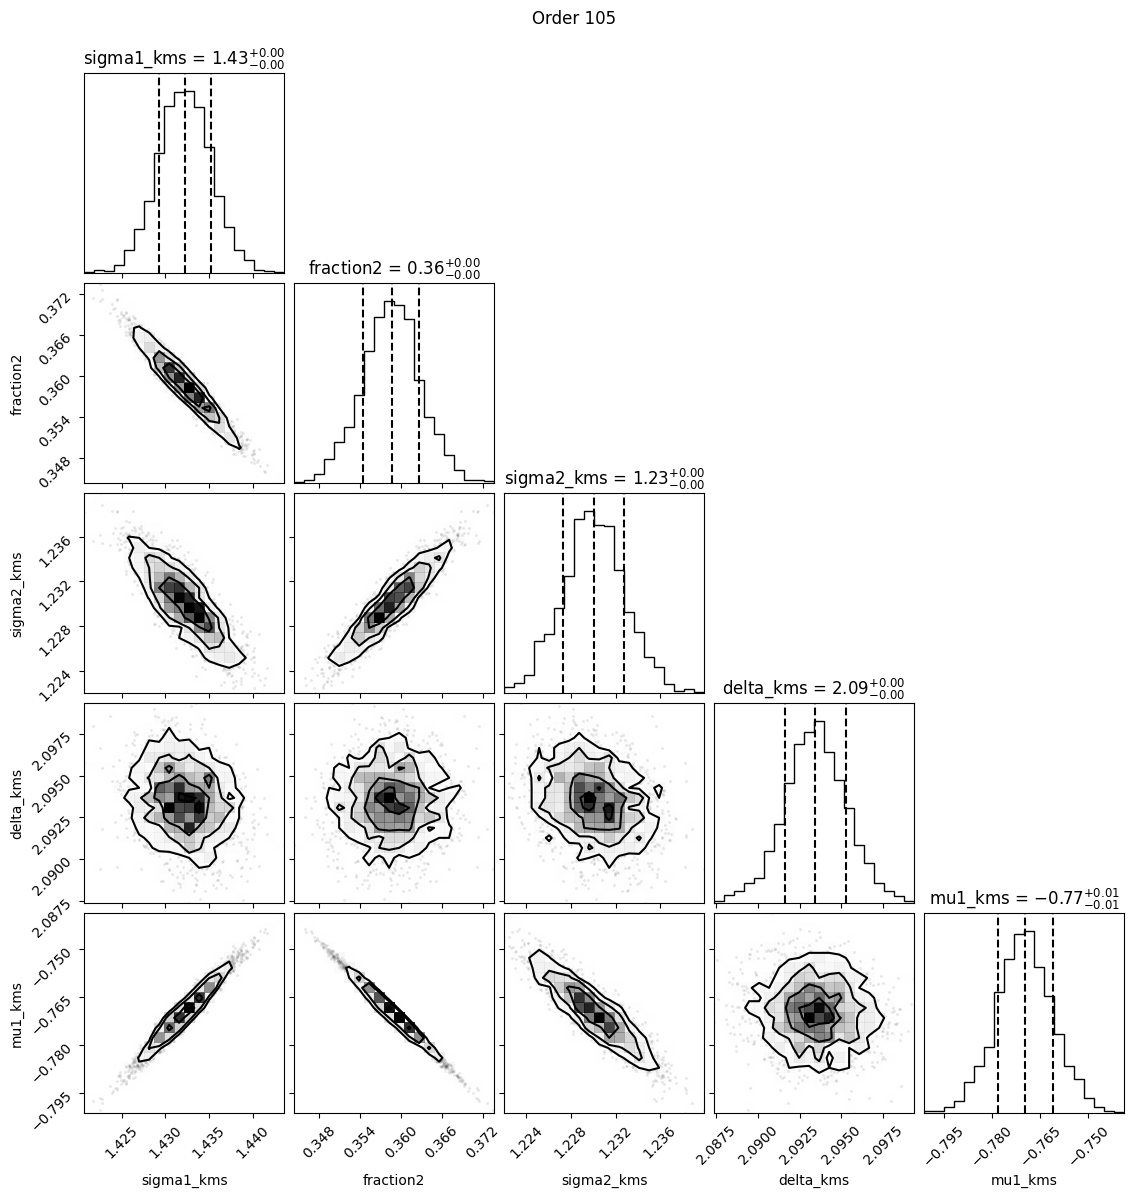

In [7]:
for o in common.orders:
    fig = corner.corner(
        o.shape_samples,
        labels=o.shape_names,
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
    );
    fig.suptitle(f"Order {o.data.order}", y=1.02)

## Check residuals

Plot the per-line residual RMS against wavelength, relative to both the model peak and the pixel noise, to identify poorly fitted lines.

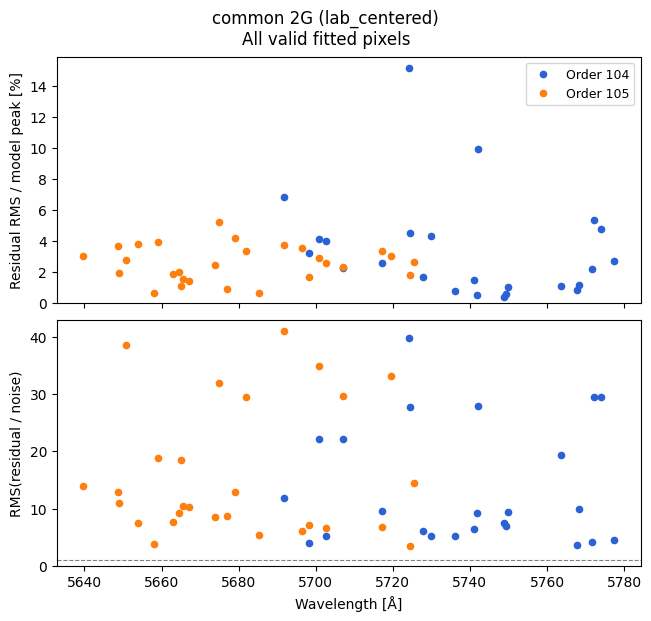

In [8]:
common.plot_residual_summary();

## Save results

Save parameter tables, residual metrics, posterior samples, input metadata, and all diagnostic figures. Choose an empty or new output directory. The figures subdirectory includes every line-fit page (with baseline), the overlay, a corner plot for each order, and the residual summary. Reload the result later with `gaoesrvip.load_result(output_dir)` and use `save_analysis_figures(restored, "new_figure_directory")` to regenerate the figures without refitting.

In [9]:
'''
output_dir = "./thar_ip_analysis_for_jaxstar"
saved_dir = common.save(output_dir, figures=False)
save_analysis_figures(common, saved_dir / "figures")
print(f"Results saved to {saved_dir.resolve()}")
'''

'\noutput_dir = "./thar_ip_analysis_for_jaxstar"\nsaved_dir = common.save(output_dir, figures=False)\nsave_analysis_figures(common, saved_dir / "figures")\nprint(f"Results saved to {saved_dir.resolve()}")\n'

## Run the full analysis in one call

You can also use `analyze_thar_ip_2g` to select lines, fit the IP, and save the results and diagnostic figures in a single call.

In [10]:
from gaoesrvip import analyze_thar_ip_2g

result = analyze_thar_ip_2g(
    thar=thar,
    wavelength_file=wavelength_file,
    fit_spectrum=fit_spectrum,
    output_dir="thar_ip_analysis_for_jaxstar/",  
    orders=[104, 105],
    gain=1.935,
    read_noise=4.0,
    saturation=5000,
    warmup=1000, samples=1000, chains=2
)

Order 104: 24 lines, common, lab_centered, MCMC, tophat=False, baseline_degree=1



  0%|          | 0/2000 [00:00<?, ?it/s]


warmup:   5%|▌         | 100/2000 [00:06<02:07, 14.95it/s, 1023 steps of size 1.86e-05. acc. prob=0.88]


warmup:  10%|█         | 200/2000 [00:09<01:17, 23.10it/s, 127 steps of size 2.49e-02. acc. prob=0.92] 


warmup:  15%|█▌        | 300/2000 [00:10<00:49, 34.24it/s, 127 steps of size 4.68e-02. acc. prob=0.93]

...


sample:  90%|█████████ | 1800/2000 [00:31<00:02, 69.66it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample:  95%|█████████▌| 1900/2000 [00:33<00:01, 69.78it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample: 100%|██████████| 2000/2000 [00:34<00:00, 69.88it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


sample: 100%|██████████| 2000/2000 [00:34<00:00, 57.91it/s, 127 steps of size 3.48e-02. acc. prob=0.96]


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
 local_scaled[0,0]      0.40      0.00      0.40      0.40      0.40   2946.90      1.00
 local_scaled[0,1]      0.50      0.00      0.50      0.50      0.50   3174.82      1.00
 local_scaled[0,2]      0.10      0.00      0.10      0.10      0.11   2688.96      1.00
 local_scaled[1,0]      0.41      0.00      0.41      0.40      0.41   2771.83      1.00
 local_scaled[1,1]      0.50      0.00      0.50      0.50      0.50   3417.07      1.00
 local_scaled[1,2]      0.11      0.00      0.11      0.11      0.11   3041.76      1.00
 local_scaled[2,0]      0.40      0.00      0.40      0.40      0.40   3515.30      1.00
 local_scaled[2,1]      0.50      0.00      0.50      0.50      0.50   3218.49      1.00
 local_scaled[2,2]      0.10      0.00      0.10      0.10      0.10   3588.22      1.00
 local_scaled[3,0]      0.40      0.00      0.40      0.40      0.40   2905.18      1.00
 local_scaled[3,1]  